# Stage 2: Geospatial Basics, Coastal Exposure Data & Wind Regions
- GeoDataFrames, Points and Polygons
- Plotting (matplotlib) and Interactive Maps (folium)
- Real Boundary Data (Natural Earth) and Spatial Checks (`.within()`)
- Coordinate Reference Systems and Buffers (EPSG:4326 vs EPSG:3577)
- Reproducibility and Sampling (random seeds, hit rates)
- Spatial Joins to a Hazard Layer (AS/NZS 1170.2 wind regions)
## Task
Using the exposure data from Stage 1, add spatial awareness, rebuild the dataset so the properties sit in a realistic coastal zone, and attach a hazard attribute to each property. Steps to work through:
- Convert `latitude`/`longitude` into a `geometry` column with `gpd.points_from_xy()` and label it as lat/long (`EPSG:4326`)
- Load the Queensland boundary from Natural Earth's Admin 1 states/provinces dataset, and plot the points over it
- Use `.within()` to check which points fall inside Queensland (7 of 10 did, because a rectangular bounding box is not the coastline)
- Reproject to a metre-based CRS (`EPSG:3577`) so a buffer distance is a true distance, not degrees
- Build a 50 km coastal zone: shrink the all-Australia shape inward by 50 km, subtract that interior, and intersect the remaining strip with Queensland (using all of Australia means state land borders are not treated as coast)
- Sample random points in the coastal zone's bounding box and keep those inside it, then compare the sampled hit rate with the exact area ratio as a sanity check (0.057 vs 0.0603)
- Rebuild the exposure table (`policy_id`, `latitude`, `longitude`, `construction_type`, `sum_insured`), validate that all 10 points are inside Queensland and the coastal zone
- Load Geoscience Australia's AS/NZS 1170.2 wind regions, reproject to match the points, and run a left spatial join (`gpd.sjoin(..., how="left", predicate="within")`) so each property gets a wind `region` and `area`
- Check the join: `len(joined)` is still 10, no `NaN` regions, and zoomed plots show the points clearly inside their polygons
- Save the result as `exposure_data_coastal_wind.csv`
- Build a final interactive `folium` map with the wind regions, boundary, coastal zone, properties with popups, legends and a layer toggle, using helpers from `mapping.py`
*Rule of thumb: do geometry in metres, display in whichever CRS reads best.*
 
*Wind regions are labels from Geoscience Australia's indicative interpretation of AS/NZS 1170.2:2021 (CC BY 4.0), not wind speeds. See the README for attribution.*
 
*For an alternative approach guaranteeing exactly 10 valid points via rejection sampling, see `02a_qld_boundary_resampling.ipynb`.*
 
*Next: Stage 3, turning a synthetic cyclone track into a wind speed at each property.*
 

In [ ]:
# load packages
import geopandas as gpd
import pandas as pd
import folium
import numpy as np
from matplotlib.patches import Patch
import matplotlib.pyplot as plt
import os
import folium
from mapping import simplified, add_layer, add_legend

In [ ]:
# Autoreload re-imports the file whenever mapping.py changes
%load_ext autoreload
%autoreload 2

In [2]:
# your df should already exist from Stage 1, or re-load it from the CSV
df = pd.read_csv("exposure_data.csv")

In [3]:
# creating a geo-dataframe that stores lat and long in a POINT(long, lat) structure i.e. POINT(x, y)
gdf = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(df["longitude"], df["latitude"])
)

gdf

,policy_id,latitude,longitude,construction_type,sum_insured,geometry
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552)
1,2,-16.591428,152.759279,concrete_block,283696.32,POINT (152.75928 -16.59143)
2,3,-19.216073,151.659541,timber,375286.79,POINT (151.65954 -19.21607)
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161)
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778)
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807)
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303)
7,8,-17.605886,149.198051,brick_veneer,508540.66,POINT (149.19805 -17.60589)
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662)
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313)


In [4]:
# and initial check of the points on a graph
#gdf.plot()

In [5]:
# adding a map for context

# create the base map
m = folium.Map(location=[-20, 147], zoom_start=5)

# loop through each row and add a marker
for idx, row in gdf.iterrows():
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=f"Policy {row['policy_id']}"  # try adding more info here if you want
    ).add_to(m)
m.save("test_map.html")
m


(Added this markdown cell to make the folio map appear: https://github.com/microsoft/vscode-jupyter/issues/17224#issuecomment-3724749068)

In [6]:
# The points we plotted are randomly generated which is why some are out in the open ocean. 
# Instead, we can load a real QLD coastline to constrain our points.

## Natural Earth Boundaries

In [7]:
# download from website and check for name of states
world_states = gpd.read_file("https://naciscdn.org/naturalearth/10m/cultural/ne_10m_admin_1_states_provinces.zip")
world_states.columns

Index(['featurecla', 'scalerank', 'adm1_code', 'diss_me', 'iso_3166_2',
       'wikipedia', 'iso_a2', 'adm0_sr', 'name', 'name_alt',
       ...
       'FCLASS_ID', 'FCLASS_PL', 'FCLASS_GR', 'FCLASS_IT', 'FCLASS_NL',
       'FCLASS_SE', 'FCLASS_BD', 'FCLASS_UA', 'FCLASS_TLC', 'geometry'],
      dtype='str', length=122)

In [8]:
# check Queensland is an option to filter for
qld = world_states[world_states["name"] == "Queensland"]
qld


,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


In [9]:
# check Queensland is in Australia (i.e. there's no other QLDs in the world)

qld = world_states[(world_states["name"] == "Queensland") & (world_states["iso_a2"] == "AU")]
qld

,featurecla,scalerank,adm1_code,diss_me,iso_3166_2,wikipedia,iso_a2,adm0_sr,name,name_alt,...,FCLASS_ID,FCLASS_PL,FCLASS_GR,FCLASS_IT,FCLASS_NL,FCLASS_SE,FCLASS_BD,FCLASS_UA,FCLASS_TLC,geometry
1763,Admin-1 states provinces,2,AUS-2657,2657,AU-QLD,NaN,AU,5,Queensland,NaN,...,NaN,None,NaN,NaN,None,NaN,NaN,NaN,NaN,"MULTIPOLYGON (((138.00017 -16.5416, 138.00082 ..."


## Comparing points and boundaries

Matplotlib is building the font cache; this may take a moment.


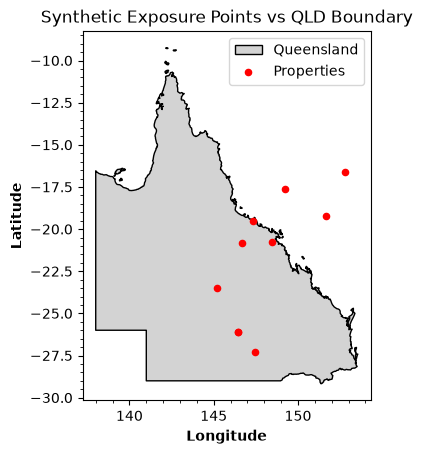

In [10]:
# plotting the QLD polygon and our randomly generated points.
# note that the geometry is a multipolygon as QLD also includes the islands 
# such as the Whitsundays which aren't connected to the mainland.

ax = qld.plot(color="lightgrey", edgecolor="black", label="Queensland")
gdf.plot(ax=ax, color="red", markersize=20, label="Properties")

ax.set_title("Synthetic Exposure Points vs QLD Boundary")
ax.set_xlabel("Longitude", fontweight="bold")
ax.set_ylabel("Latitude", fontweight="bold")

ax.legend()

ax.minorticks_on()
ax.set_axisbelow(True)

ax.figure.savefig("qld_exposure_points.png", dpi=300, bbox_inches="tight")

In [11]:
# create a column to track which points are inside/outside the polygon
# 

gdf["in_qld"] = gdf.within(qld.union_all())
gdf

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
1,2,-16.591428,152.759279,concrete_block,283696.32,POINT (152.75928 -16.59143),False
2,3,-19.216073,151.659541,timber,375286.79,POINT (151.65954 -19.21607),False
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
7,8,-17.605886,149.198051,brick_veneer,508540.66,POINT (149.19805 -17.60589),False
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [12]:
# counts the points in/out of QLD

gdf["in_qld"].value_counts()

in_qld
True     7
False    3
Name: count, dtype: int64

In [13]:
# Filter to points inside QLD

gdf_clean = gdf[gdf["in_qld"]]
gdf_clean

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
3,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
4,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
5,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
6,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
8,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
9,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [14]:
# Tidy index to stop any issues with rows later on. Makes sure index column isn't outputted to CSV.

gdf_clean = gdf[gdf["in_qld"]].reset_index(drop=True)
gdf_clean

,policy_id,latitude,longitude,construction_type,sum_insured,geometry,in_qld
0,1,-23.505519,145.164676,concrete_block,567111.74,POINT (145.16468 -23.50552),True
1,4,-20.816098,146.698713,timber,419817.11,POINT (146.69871 -20.8161),True
2,5,-26.127776,146.454600,concrete_block,473641.99,POINT (146.4546 -26.12778),True
3,6,-26.128066,146.467236,brick_veneer,671105.58,POINT (146.46724 -26.12807),True
4,7,-27.302997,147.433938,timber,319804.27,POINT (147.43394 -27.303),True
5,9,-20.786620,148.455560,brick_veneer,555448.74,POINT (148.45556 -20.78662),True
6,10,-19.503129,147.329833,brick_veneer,227870.25,POINT (147.32983 -19.50313),True


In [15]:
# adding a map for context

# create the base map
n = folium.Map(location=[-20, 147], zoom_start=5)

# dictionary to define colour of markers on map with respect to construction type
colour_map = {
    "timber": "red",
    "brick_veneer": "orange",
    "concrete_block": "blue",
}

# Check that every construction type has a colour before creating the map
set(gdf_clean["construction_type"]) - set(colour_map)

set()

In [ ]:
# loop through each row and add a marker
for idx, row in gdf_clean.iterrows():
    popup_text = (
        f"<b>Policy {row['policy_id']}</b><br>"
        f"Construction: {row['construction_type']}<br>"
        f"Sum insured: ${row['sum_insured']:,.0f}<br>"
        f"Lat/Long: {row['latitude']:.2f}, {row['longitude']:.2f}"
    )
    folium.Marker(
        location=[row["latitude"], row["longitude"]],
        popup=folium.Popup(popup_text, max_width=250),
        tooltip=f"Policy {row['policy_id']}",
        icon=folium.Icon(color=colour_map[row["construction_type"]]),
    ).add_to(n)

n.save("qld_exposure_map_clean.html")
n

## Coastal Buffer

<Axes: >

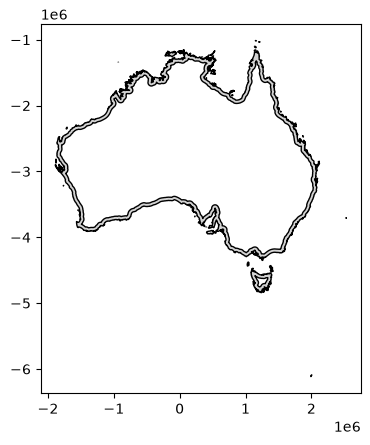

In [17]:
# Bulding the coastal shape

# Joins the states together and reprojects so distances are in m instead of degrees
aus = world_states[world_states["iso_a2"] == "AU"].to_crs("EPSG:3577")
aus_shape = aus.union_all()

# Shriks the shape inwards by 50km, inside of which is the deep interior 
# i.e. coastal areas are in that first 50km fom the coast
interior = aus_shape.buffer(-50_000)

gpd.GeoSeries([aus_shape, interior]).plot(color=["lightgrey", "white"], edgecolor="black")

In [18]:
# Check coordinate reference system
print(qld.crs)

EPSG:4326


In [19]:
# 1. label your points as lat/long (this doesn't change any coordinates)
gdf = gdf.set_crs("EPSG:4326")
print(gdf.crs)

# 2. make a metre-based copy of Queensland
qld_m = qld.to_crs("EPSG:3577")
print(qld_m.crs)

EPSG:4326
EPSG:3577


<Axes: title={'center': 'QLD Coastal Zone'}>

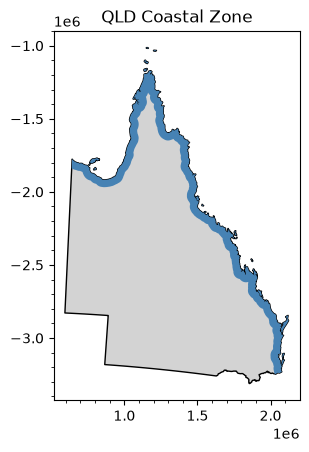

In [20]:
# Build the coastal zone for QLD only 

# removes deep interior, leaving coastal band
coastal_strip = aus_shape.difference(interior)
# only keeps the part of the band that's inside QLD
qld_coastal = qld_m.union_all().intersection(coastal_strip)

ax = qld_m.plot(color="lightgrey", edgecolor="black")

ax.set_title("QLD Coastal Zone")
ax.minorticks_on()
ax.set_axisbelow(True)

gpd.GeoSeries([qld_coastal], crs="EPSG:3577").plot(ax=ax, color="steelblue")

In [21]:
# Check coastal area is smaller than QLD area
print(qld_coastal.area / 1e6)          # km²
print(qld_m.union_all().area / 1e6)    # km²
print(qld_coastal.area/qld_m.union_all().area*100) # %

199858.19644621795
1730148.5959606958
11.551504703862916


## Sampling points inside the coastal zone

In [22]:
np.random.seed(42)

minx, miny, maxx, maxy = qld_coastal.bounds   # bounding box, in metres

n_candidates = 2000

x = np.random.uniform(minx, maxx, size=n_candidates)
y = np.random.uniform(miny, maxy, size=n_candidates)

candidates = gpd.GeoDataFrame(geometry=gpd.points_from_xy(x, y), crs="EPSG:3577")

# 1. add an in_coastal column using .within() against qld_coastal
# 2. keep only the True rows and take the first 10
# 3. convert to lat/long with .to_crs("EPSG:4326")



In [23]:

# add column to show which candidate points are in the coastal region
candidates["in_qld_coast"] = candidates.within(qld_coastal)

# filter for poins that fall in the coastal region
qld_coast_candidates = candidates[candidates["in_qld_coast"]]

# reset row index
qld_coast_candidates_clean = candidates[candidates["in_qld_coast"]].reset_index(drop=True)

# Take top 10 rows
ten_qld_coast = qld_coast_candidates_clean.head(10)

# convert lat and long to new crs
coastal_points = ten_qld_coast.to_crs("EPSG:4326")

coastal_points

,geometry,in_qld_coast
0,POINT (145.03119 -15.0185),True
1,POINT (145.75704 -18.29233),True
2,POINT (152.47841 -25.09739),True
3,POINT (146.00706 -18.67623),True
4,POINT (144.89958 -15.27601),True
5,POINT (152.26914 -24.75474),True
6,POINT (144.71581 -15.00074),True
7,POINT (149.3053 -21.8457),True
8,POINT (141.54095 -16.43731),True
9,POINT (142.1786 -12.78253),True


<Axes: >

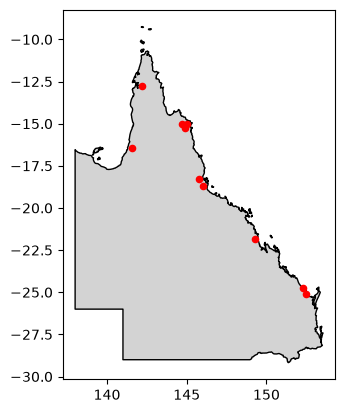

In [24]:
# Visually check location of points
ax = qld.plot(color="lightgrey", edgecolor="black")
coastal_points.plot(ax=ax, color="red", markersize=20)

In [25]:
# Checking how many candidates were valid (%)
print(candidates["in_qld_coast"].mean())

0.057


In [26]:
# check the estimate with a quick area calculation - it should be close to .mean(). 
# If the two numbers are far apart, something is wrong with the sampling or the CRS.
minx, miny, maxx, maxy = qld_coastal.bounds
box_area = (maxx - minx) * (maxy - miny)
print(qld_coastal.area / box_area)

0.060311517787657684


## Building the Exposure Table

In [27]:
# 1. make sure you're working in lat/long and have exactly 10 rows
coastal_points = coastal_points.to_crs("EPSG:4326").head(10).reset_index(drop=True)

# 2. build the table from the geometry
materials = ["timber", "brick_veneer", "concrete_block"]

df_coastal = pd.DataFrame({
    "policy_id": np.array([1,2,3,4,5,6,7,8,9,10]),                    
    "latitude": coastal_points.geometry.y,
    "longitude": coastal_points.geometry.x,
    "construction_type": np.random.choice(materials, size=10),           
    "sum_insured": np.random.uniform(2e5, 8e5, size=10).round(2), 
})

# 3. save without the index column
df_coastal.to_csv("qld_exposure_coast.csv", index=False)  

df_coastal 

,policy_id,latitude,longitude,construction_type,sum_insured
0,1,-15.018502,145.031188,brick_veneer,445073.35
1,2,-18.292329,145.757040,timber,607818.33
2,3,-25.097391,152.478414,timber,234008.26
3,4,-18.676231,146.007062,concrete_block,220803.62
4,5,-15.276010,144.899578,concrete_block,435146.34
5,6,-24.754739,152.269141,timber,618298.22
6,7,-15.000745,144.715814,timber,316061.21
7,8,-21.845701,149.305298,brick_veneer,584902.69
8,9,-16.437310,141.540951,concrete_block,355896.88
9,10,-12.782526,142.178599,brick_veneer,731651.67


In [28]:
gdf_coastal = gpd.GeoDataFrame(
    df_coastal,
    geometry=gpd.points_from_xy(df_coastal["longitude"], df_coastal["latitude"]),
    crs="EPSG:4326",
)

In [29]:
print(gdf_coastal.within(qld.union_all()).value_counts())
print(gdf_coastal.to_crs("EPSG:3577").within(qld_coastal).value_counts())

True    10
Name: count, dtype: int64
True    10
Name: count, dtype: int64


## Wind Regions

In [31]:
# Read for columns
wind = gpd.read_file("/Users/kiranchotalia/Documents/Modelling/catmodel-project/data/wind_regions/as1170windzones.shp")
print(wind.crs)
print(wind.columns)
wind.head()

EPSG:7844
Index(['area', 'region', 'id', 'Shape_Leng', 'Shape_Area', 'geometry'], dtype='str')


,area,region,id,Shape_Leng,Shape_Area,geometry
0,Interior,A0,0,117.915204,501.462354,"POLYGON ((135.10242 -15.80385, 135.27839 -15.9..."
1,Lower west coast,A1,0,49.037507,26.092484,"MULTIPOLYGON (((117.86947 -35.1851, 117.86947 ..."
2,NSW,A2,0,40.484248,4.451232,"MULTIPOLYGON (((150.05118 -37.26354, 150.05114..."
3,Lord Howe Island,A2,12,0.486986,0.001548,"MULTIPOLYGON (((159.07298 -31.59956, 159.07276..."
4,NSW,A3,0,19.222788,12.225991,"POLYGON ((149.59972 -35.97419, 149.57344 -36.1..."


In [32]:
print(wind["area"].value_counts())
print(wind["region"].value_counts())

area
Pilbara             3
NSW                 2
Mid west            2
Northern coast      2
Interior            1
Lower west coast    1
Lord Howe Island    1
Tasmania            1
Southern coast      1
SE Queensland       1
Norfolk Island      1
West                1
Torres Strait       1
Christmas Island    1
Cocos Island        1
Name: count, dtype: int64
region
B2    6
C     4
A2    2
B1    2
A0    1
A1    1
A3    1
A4    1
A5    1
D     1
Name: count, dtype: int64


In [39]:
## Checking which region which was assigned to which property ##

# Which area goes with which region? Inspect data.
print(wind[["area", "region"]].sort_values("region").to_string())

# match the coordinate referenece systems, making layers comparable
wind = wind.to_crs(gdf_coastal.crs)

# If the point is within a polygon, the columns are filled from that polygon’s row. 
# If it isn’t, a left join still keeps the row but fills the three columns with NaN.
joined = gpd.sjoin(gdf_coastal, wind[["area", "region", "geometry"]], how="left", predicate="within")

# check there are no duplicates and no dropped rows. Should equal 10
print(len(joined))

# check every property found a polygon. Should be 0
print(joined["region"].isna().sum())

# check the region index
print(joined[["policy_id", "region", "index_right"]])

# check area and region
print(joined[["policy_id", "latitude", "longitude", "area", "region"]])

# count how many of each region are in my dataset
print(joined["region"].value_counts(dropna=False))



                area region
0           Interior     A0
1   Lower west coast     A1
2                NSW     A2
3   Lord Howe Island     A2
4                NSW     A3
5           Tasmania     A4
6     Southern coast     A5
7      SE Queensland     B1
8     Norfolk Island     B1
14  Christmas Island     B2
13     Torres Strait     B2
12    Northern coast     B2
9               West     B2
10          Mid west     B2
11           Pilbara     B2
18      Cocos Island      C
15    Northern coast      C
16          Mid west      C
17           Pilbara      C
19           Pilbara      D
10
0
   policy_id region  index_right
0          1      C           15
1          2      C           15
2          3     B1            7
3          4      C           15
4          5      C           15
5          6      C           15
6          7      C           15
7          8      C           15
8          9      C           15
9         10      C           15
   policy_id   latitude   longitude         

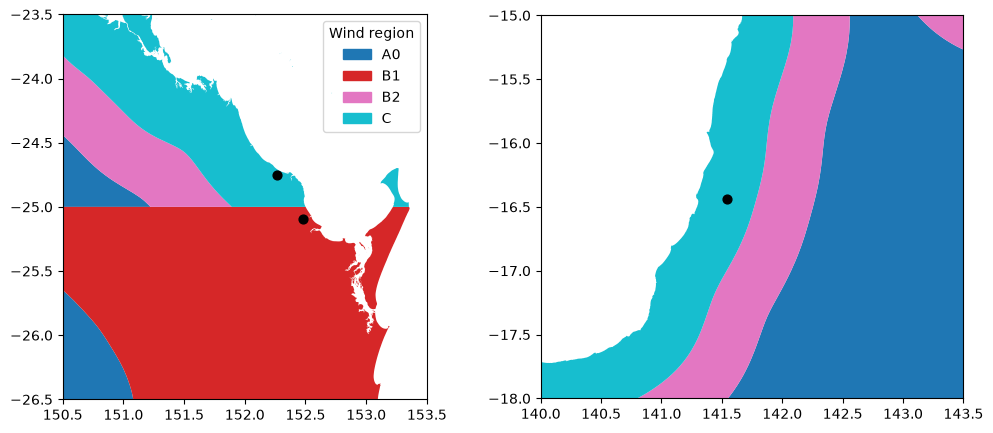

In [ ]:
## Visualising points and regions ##

# colours were not matching with previous graph
# ax = wind.cx[138:154, -29:-10].plot(column="region", legend=True, figsize=(7, 8))
# joined.plot(ax=ax, color="black", markersize=20)

# Plotting wind regions with consistent colours
region_colours = {
    "A0": "#1f77b4",   # blue
    "B1": "#d62728",   # red
    "B2": "#e377c2",   # pink
    "C":  "#17becf",   # cyan
}
def plot_regions(ax, data):
    for reg, grp in data.groupby("region"):
        grp.plot(ax=ax, color=region_colours.get(reg, "lightgrey"))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
views = [(150.5, 153.5, -26.5, -23.5), (140, 143.5, -18, -15)]

for ax, (xmin, xmax, ymin, ymax) in zip(axes, views):
    plot_regions(ax, wind)
    joined.plot(ax=ax, color="black", markersize=40)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)

handles = [Patch(color=c, label=r) for r, c in region_colours.items()]
axes[0].legend(handles=handles, title="Wind region")

In [ ]:
# save policy and wind region dataset
exposure_wind = joined.drop(columns=["index_right", "geometry"])
exposure_wind.to_csv("exposure_data_coastal_wind.csv", index=False)

## Complete Map
- Queensland boundary
- coastal zone
- wind regions
- colour-coded properties
- legend
- layer toggle

In [ ]:
# colour_map = {
#     "timber": "#d73027",
#     "brick_veneer": "#fc8d59",
#     "concrete_block": "#4575b4",
# }

# # lighter copies of the boundaries, for display only
# qld_simple = qld.copy()
# qld_simple["geometry"] = qld_simple.geometry.simplify(0.01)

# coastal_ll = (
#     gpd.GeoSeries([qld_coastal], crs="EPSG:3577")
#     .to_crs("EPSG:4326")
#     .simplify(0.01)
# )

# # wind region colours
# region_colours = {
#     "A0": "#1f77b4",
#     "B1": "#d62728",
#     "B2": "#e377c2",
#     "C":  "#17becf",
# }

# # Queensland only, simplified for display (both layers are already in EPSG:4326)
# wind_qld = gpd.clip(wind[["region", "area", "geometry"]], qld)
# wind_qld["geometry"] = wind_qld.geometry.simplify(0.01)

# # base map, zoomed to the points
# final_map = folium.Map(location=[-20, 147], zoom_start=5)
# minx, miny, maxx, maxy = gdf_coastal.total_bounds
# final_map.fit_bounds([[miny, minx], [maxy, maxx]])

# # boundary layers
# folium.GeoJson(
#     qld_simple,
#     name="Queensland",
#     style_function=lambda f: {"color": "black", "weight": 1, "fillOpacity": 0.05},
# ).add_to(final_map)

# folium.GeoJson(
#     coastal_ll,
#     show='False',
#     name="50 km coastal zone",
#     style_function=lambda f: {"color": "#4575b4", "weight": 0.5, "fillColor": "#4575b4", "fillOpacity": 0.25},
# ).add_to(final_map)

# folium.GeoJson(
#     wind_qld,
#     name="Wind regions (AS/NZS 1170.2)",
#     style_function=lambda f: {
#         "fillColor": region_colours.get(f["properties"]["region"], "lightgrey"),
#         "color": "none",
#         "fillOpacity": 0.4,
#     },
#     tooltip=folium.GeoJsonTooltip(fields=["region", "area"], aliases=["Wind region", "Area"]),
# ).add_to(final_map)

# # property markers
# properties = folium.FeatureGroup(name="Properties")
# for _, row in joined.iterrows():
#     popup_text = (
#         f"<b>Policy {row['policy_id']}</b><br>"
#         f"Construction: {row['construction_type']}<br>"
#         f"Sum insured: ${row['sum_insured']:,.0f}<br>"
#         f"Lat/Long: {row['latitude']:.2f}, {row['longitude']:.2f}<br>"
#         f"Wind region: {row['region']}<br>"
#     )
#     folium.CircleMarker(
#         location=[row["latitude"], row["longitude"]],
#         radius=5,
#         color=colour_map[row["construction_type"]],
#         fill=True,
#         fill_opacity=0.85,
#         popup=folium.Popup(popup_text, max_width=250),
#         tooltip=f"Policy {row['policy_id']}",
#     ).add_to(properties)
# properties.add_to(final_map)

# # layer toggle
# folium.LayerControl().add_to(final_map)

# # legend (folium has no built-in one)
# items = "".join(
#     f'<span style="color:{c};font-size:16px;">&#9679;</span> {k}<br>'
#     for k, c in colour_map.items()
# )
# legend_html = (
#     '<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; '
#     'background: white; padding: 10px 12px; border: 1px solid grey; '
#     'border-radius: 6px; font-size: 13px;">'
#     f"<b>Construction type</b><br>{items}</div>"
# )
# final_map.get_root().html.add_child(folium.Element(legend_html))

# wind_items = "".join(
#     f'<span style="color:{c};font-size:16px;">&#9632;</span> {k}<br>'
#     for k, c in region_colours.items()
# )
# wind_legend_html = (
#     '<div style="position: fixed; bottom: 30px; right: 30px; z-index: 9999; '
#     'background: white; padding: 10px 12px; border: 1px solid grey; '
#     'border-radius: 6px; font-size: 13px;">'
#     f"<b>Wind region</b><br>{wind_items}</div>"
# )
# final_map.get_root().html.add_child(folium.Element(wind_legend_html))

# os.makedirs("outputs", exist_ok=True)
# final_map.save("outputs/qld_coastal_exposure_wind_map.html")
# final_map

In [57]:
# more efficient cell than the version above

COLOUR_MAP = {"timber": "#d73027", "brick_veneer": "#fc8d59", "concrete_block": "#4575b4"}
REGION_COLOURS = {"A0": "#1f77b4", "B1": "#d62728", "B2": "#e377c2", "C": "#17becf"}

# layers prepared for display
qld_simple = simplified(qld)
coastal_ll = simplified(
    gpd.GeoDataFrame(geometry=[qld_coastal], crs="EPSG:3577").to_crs("EPSG:4326")
)
wind_qld = simplified(gpd.clip(wind[["region", "area", "geometry"]], qld))

# map
m = folium.Map(location=[-20, 147], zoom_start=5)
minx, miny, maxx, maxy = joined.total_bounds
m.fit_bounds([[miny, minx], [maxy, maxx]])

add_layer(
    m, wind_qld, "Wind regions (AS/NZS 1170.2)",
    lambda f: {"fillColor": REGION_COLOURS.get(f["properties"]["region"], "lightgrey"),
               "color": "none", "fillOpacity": 0.4},
    tooltip=folium.GeoJsonTooltip(fields=["region", "area"], aliases=["Wind region", "Area"]),
)
add_layer(m, qld_simple, "Queensland", {"color": "black", "weight": 1, "fillOpacity": 0.05})
add_layer(
    m, coastal_ll, "50 km coastal zone",
    {"color": "#4575b4", "weight": 0.5, "fillColor": "#4575b4", "fillOpacity": 0.25},
    show=False,
)

# properties
properties = folium.FeatureGroup(name="Properties")
for r in joined.itertuples():
    popup = (
        f"<b>Policy {r.policy_id}</b><br>"
        f"Construction: {r.construction_type}<br>"
        f"Sum insured: ${r.sum_insured:,.0f}<br>"
        f"Lat/Long: {r.latitude:.2f}, {r.longitude:.2f}<br>"
        f"Wind region: {r.region}"
    )
    folium.CircleMarker(
        location=[r.latitude, r.longitude],
        radius=5,
        color=COLOUR_MAP[r.construction_type],
        fill=True,
        fill_opacity=0.85,
        popup=folium.Popup(popup, max_width=250),
        tooltip=f"Policy {r.policy_id}",
    ).add_to(properties)
properties.add_to(m)

folium.LayerControl().add_to(m)
add_legend(m, "Construction type", COLOUR_MAP, corner="left")
add_legend(m, "Wind region", REGION_COLOURS, corner="right", symbol="&#9632;")

os.makedirs("outputs", exist_ok=True)
m.save("outputs/qld_coastal_exposure_wind_map.html")
m